# Predicting Breast Cancer Recurrence in Python (WPBC)

A Python replication of my R analysis of the Wisconsin Prognostic Breast Cancer (WPBC) data. The question: using features measured at surgery, can we predict which patients will have a recurrence, and how honest can we be about how well the models do?

**What this notebook does**

1. Loads and cleans the data (drops 4 patients with a missing node count, leaving 194).
2. Splits it 70/30 into training and test sets.
3. Fits seven models: reduced logistic regression, lasso logistic regression, a pruned decision tree, bagging, a random forest, a class-balanced random forest and gradient boosting. All tuning uses cross-validation on the **training set only**.
4. Evaluates every model once on the held-out test set against a naive "always no recurrence" baseline, using accuracy, sensitivity, specificity and AUC.
5. Checks how stable the conclusions are with repeated cross-validation, and chooses a decision threshold without touching the test set.

**Data.** Wolberg, W., Street, W. and Mangasarian, O. (1995). *Breast Cancer Wisconsin (Prognostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5GK50 (CC BY 4.0). Download `wpbc.data` from the UCI page and save it as `data/wpbc.data`. The data are not included with this notebook.

## Authorship and tools

_Edit this cell so it states exactly what you wrote and what AI tools helped with._ This notebook was drafted with help from Claude (Anthropic). Before you publish or submit it, work through each cell and make sure you can explain it, then record here what you wrote yourself, what Claude drafted, and what you checked.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, log_loss, confusion_matrix
from imblearn.ensemble import BalancedRandomForestClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 1
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110

## 1. Load and clean the data

In [2]:
DATA_PATH = Path("data/wpbc.data")
if not DATA_PATH.exists():
    raise FileNotFoundError("Download wpbc.data from the UCI page (see the top of this notebook) and save it in data/.")

feature_names = ["radius", "texture", "perimeter", "area", "smoothness",
                 "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
columns = ["id", "status", "time"]
columns += [f"{kind}_{f}" for kind in ["mean", "SE", "worst"] for f in feature_names]
columns += ["tsize", "pnodes"]

raw = pd.read_csv(DATA_PATH, header=None, names=columns, na_values="?")
print("Raw data:", raw.shape, "| recurrences (R):", (raw.status == "R").sum())
print("Missing values:", raw.isna().sum()[raw.isna().sum() > 0].to_dict())

# Drop the 4 patients with a missing node count (<2.1%), the ID, and follow-up time.
# Follow-up time is not a predictor: it is only known in hindsight, and using it properly needs survival analysis.
df = raw.dropna(subset=["pnodes"]).drop(columns=["id", "time"]).reset_index(drop=True)
y = (df["status"] == "R").astype(int)
X = df.drop(columns="status")

print(f"\nClean data: {X.shape[0]} patients, {X.shape[1]} predictors")
print(f"Recurrences: {y.sum()} ({y.mean():.1%}); no recurrence: {(1 - y).sum()} ({1 - y.mean():.1%})")
print(f"A model that always predicts 'no recurrence' is right {(1 - y.mean()):.1%} of the time.")

Raw data: (198, 35) | recurrences (R): 47
Missing values: {'pnodes': 4}

Clean data: 194 patients, 32 predictors
Recurrences: 46 (23.7%); no recurrence: 148 (76.3%)
A model that always predicts 'no recurrence' is right 76.3% of the time.


## 2. Train/test split

A 70/30 split with 136 training and 58 test patients. The split is stratified by outcome, so both sets keep roughly the same share of recurrences (this is a small data set with a rare outcome). The test set is used once, at the end.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=58, stratify=y, random_state=SEED)
print(f"Train: {len(X_train)} patients, {y_train.sum()} recurrences")
print(f"Test:  {len(X_test)} patients, {y_test.sum()} recurrences")
naive_acc = 1 - y_test.mean()
print(f"Naive 'always no recurrence' accuracy on the test set: {naive_acc:.3f}")

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

Train: 136 patients, 32 recurrences
Test:  58 patients, 14 recurrences
Naive 'always no recurrence' accuracy on the test set: 0.759


## 3. Reduced logistic regression and a likelihood-ratio test

The 30 image features are highly correlated (they are mean, standard error and "worst" values of the same ten nuclear measurements), so a full logistic regression would be unstable. Instead I use one representative feature per clinical concept (the "worst" values of radius, texture, concave points and symmetry) plus tumour size and node count.

In [4]:
reduced = ["worst_radius", "worst_texture", "worst_concave_points", "worst_symmetry", "tsize", "pnodes"]

# statsmodels gives the inference output (standard errors, p-values, odds ratios).
logit = sm.Logit(y_train, sm.add_constant(X_train[reduced])).fit(disp=0)
print(logit.summary2().tables[1].round(3))

odds = np.exp(pd.concat([logit.params, logit.conf_int()], axis=1))
odds.columns = ["odds_ratio", "ci_2.5%", "ci_97.5%"]
print("\nOdds ratios (Wald 95% intervals):")
print(odds.round(3))

# Variance inflation factors for the reduced model.
Xr = X_train[reduced]
vif = {c: 1 / (1 - sm.OLS(Xr[c], sm.add_constant(Xr.drop(columns=c))).fit().rsquared) for c in reduced}
print("\nVIFs:", {k: round(v, 2) for k, v in vif.items()})

# Likelihood-ratio test: do the four nuclear features add anything to tumour size and node count?
small = sm.Logit(y_train, sm.add_constant(X_train[["tsize", "pnodes"]])).fit(disp=0)
lr_stat = 2 * (logit.llf - small.llf)
lr_df = len(reduced) - 2
print(f"\nLR test (4 nuclear features added to tsize + pnodes): "
      f"chi2 = {lr_stat:.2f}, df = {lr_df}, p = {chi2.sf(lr_stat, lr_df):.4f}")

                      Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
const                -2.440     1.971 -1.238  0.216  -6.303   1.423
worst_radius          0.097     0.064  1.502  0.133  -0.030   0.223
worst_texture        -0.035     0.037 -0.928  0.353  -0.108   0.039
worst_concave_points -4.201     6.373 -0.659  0.510 -16.692   8.289
worst_symmetry        0.576     3.579  0.161  0.872  -6.439   7.592
tsize                 0.144     0.109  1.318  0.188  -0.070   0.359
pnodes                0.095     0.042  2.268  0.023   0.013   0.178

Odds ratios (Wald 95% intervals):
                      odds_ratio  ci_2.5%  ci_97.5%
const                      0.087    0.002     4.151
worst_radius               1.102    0.971     1.250
worst_texture              0.966    0.898     1.039
worst_concave_points       0.015    0.000  3978.938
worst_symmetry             1.780    0.002  1981.579
tsize                      1.155    0.932     1.432
pnodes                     1.100    1.013     1.195

VIFs

## 4. The models

Every model below is tuned on the training set only.

### Lasso logistic regression (1-standard-error rule)

The lasso uses all 32 predictors and shrinks some coefficients to exactly zero. I pick the penalty with 10-fold cross-validation, using the most regularised model whose cross-validated log loss is within one standard error of the best, as `lambda.1se` does in R's glmnet.

In [5]:
def lasso_pipe(C):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=5000))

Cs = np.logspace(-3, 1, 40)
means, ses = [], []
for C in Cs:
    s = -cross_val_score(lasso_pipe(C), X_train, y_train, cv=cv10, scoring="neg_log_loss")
    means.append(s.mean()); ses.append(s.std(ddof=1) / np.sqrt(len(s)))
means, ses = np.array(means), np.array(ses)

i_best = means.argmin()
limit = means[i_best] + ses[i_best]
C_1se = Cs[means <= limit].min()          # smallest C = strongest penalty within 1 SE
C_min = Cs[i_best]
print(f"Best C (min CV log loss): {C_min:.4f}; 1-SE rule C: {C_1se:.4f}")

for label, C in [("1-SE rule", C_1se), ("minimum", C_min)]:
    fit = lasso_pipe(C).fit(X_train, y_train)
    coefs = pd.Series(fit[-1].coef_[0], index=X_train.columns)
    nz = coefs[coefs != 0].sort_values(key=abs, ascending=False)
    print(f"\nNonzero coefficients at the {label} penalty: {len(nz)}")
    print(nz.round(3).head(10).to_string() if len(nz) else "  (none: the model is intercept-only)")

lasso = lasso_pipe(C_1se).fit(X_train, y_train)

Best C (min CV log loss): 0.7444; 1-SE rule C: 0.1125

Nonzero coefficients at the 1-SE rule penalty: 3
pnodes            0.218
tsize             0.070
SE_compactness   -0.017

Nonzero coefficients at the minimum penalty: 12
pnodes                    0.605
worst_smoothness          0.564
SE_perimeter              0.449
mean_fractal_dimension   -0.447
SE_concave_points        -0.355
SE_texture               -0.298
tsize                     0.199
mean_texture             -0.169
SE_compactness           -0.160
worst_compactness        -0.088


### Decision tree (cost-complexity pruning)

Grow a full tree, then choose how far to prune it with 10-fold cross-validated misclassification error. If no split improves the cross-validated error, the pruned tree collapses to a single node that predicts the majority class.

In [6]:
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(path.ccp_alphas)
cv_err = np.array([
    1 - cross_val_score(DecisionTreeClassifier(random_state=SEED, ccp_alpha=a), X_train, y_train,
                        cv=cv10, scoring="accuracy").mean()
    for a in alphas])
best_alpha = alphas[np.flatnonzero(cv_err == cv_err.min())[-1]]    # simplest tree among ties
tree = DecisionTreeClassifier(random_state=SEED, ccp_alpha=best_alpha).fit(X_train, y_train)
print(f"Chosen ccp_alpha = {best_alpha:.4f}; leaves in pruned tree: {tree.get_n_leaves()}; "
      f"CV error {cv_err.min():.3f} (error of the unsplit root: {1 - y_train.mean():.3f})")

Chosen ccp_alpha = 0.0431; leaves in pruned tree: 1; CV error 0.265 (error of the unsplit root: 0.765)


### Bagging, random forest and class-balanced random forest

* **Bagging**: every split may use all predictors.
* **Random forest**: each split considers a random subset (the square root of the number of predictors).
* **Balanced random forest**: each tree is grown on a bootstrap sample with equal numbers of recurrence and non-recurrence patients, a direct remedy for the 76% / 24% imbalance.

In [7]:
bagging = RandomForestClassifier(n_estimators=500, max_features=None, oob_score=True, random_state=SEED).fit(X_train, y_train)
rf      = RandomForestClassifier(n_estimators=500, max_features="sqrt", oob_score=True, random_state=SEED).fit(X_train, y_train)
brf     = BalancedRandomForestClassifier(n_estimators=500, max_features="sqrt", sampling_strategy="all",
                                         replacement=True, bootstrap=False, random_state=SEED).fit(X_train, y_train)

for name, m in [("Bagging", bagging), ("Random forest", rf)]:
    print(f"{name}: out-of-bag error = {1 - m.oob_score_:.3f}")
print("Balanced forest trained on equal class counts per tree (no OOB score reported by imblearn).")

Bagging: out-of-bag error = 0.272
Random forest: out-of-bag error = 0.257
Balanced forest trained on equal class counts per tree (no OOB score reported by imblearn).


### Gradient boosting

Shallow trees (two splits each) with a small learning rate of 0.01. The number of trees is chosen by 5-fold cross-validated log loss on the training set.

In [8]:
def make_gbm(n):
    return GradientBoostingClassifier(n_estimators=n, learning_rate=0.01, max_leaf_nodes=3, random_state=SEED)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
N_MAX = 1000
stage_loss = np.zeros(N_MAX)
for tr, va in cv5.split(X_train, y_train):
    m = make_gbm(N_MAX).fit(X_train.iloc[tr], y_train.iloc[tr])
    for k, p in enumerate(m.staged_predict_proba(X_train.iloc[va])):
        stage_loss[k] += log_loss(y_train.iloc[va], p[:, 1], labels=[0, 1])
best_trees = int(stage_loss.argmin() + 1)
print(f"CV-optimal number of trees: {best_trees} (out of {N_MAX})")
gbm = make_gbm(best_trees).fit(X_train, y_train)

CV-optimal number of trees: 38 (out of 1000)


## 5. Test-set comparison

Each model is evaluated once on the held-out test set at the default 0.5 threshold. Accuracy alone is misleading when 76% of patients do not recur, so I report **sensitivity** (the share of recurrences correctly flagged), **specificity** and **AUC** (how well the model ranks patients by risk, independent of any threshold).

In [9]:
log_clf = make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5000)).fit(X_train[reduced], y_train)

probs = {
    "Logistic (reduced)":        log_clf.predict_proba(X_test[reduced])[:, 1],
    "Lasso logistic":            lasso.predict_proba(X_test)[:, 1],
    "Pruned tree":               tree.predict_proba(X_test)[:, 1],
    "Bagging":                   bagging.predict_proba(X_test)[:, 1],
    "Random forest":             rf.predict_proba(X_test)[:, 1],
    "Random forest (balanced)":  brf.predict_proba(X_test)[:, 1],
    "Boosting":                  gbm.predict_proba(X_test)[:, 1],
}

def metrics(y_true, p, thr=0.5):
    pred = (p > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"Accuracy": (tp + tn) / len(y_true),
            "Sensitivity": tp / (tp + fn),
            "Specificity": tn / (tn + fp),
            "AUC": roc_auc_score(y_true, p)}

results = pd.DataFrame({k: metrics(y_test, v) for k, v in probs.items()}).T.round(3)
display(results)
print(f"Naive 'always no recurrence' accuracy: {naive_acc:.3f}")

,Accuracy,Sensitivity,Specificity,AUC
Logistic (reduced),0.707,0.143,0.886,0.617
Lasso logistic,0.707,0.000,0.932,0.529
Pruned tree,0.759,0.000,1.000,0.500
Bagging,0.759,0.214,0.932,0.653
Random forest,0.810,0.286,0.977,0.662
Random forest (balanced),0.724,0.571,0.773,0.601
Boosting,0.759,0.000,1.000,0.533


Naive 'always no recurrence' accuracy: 0.759


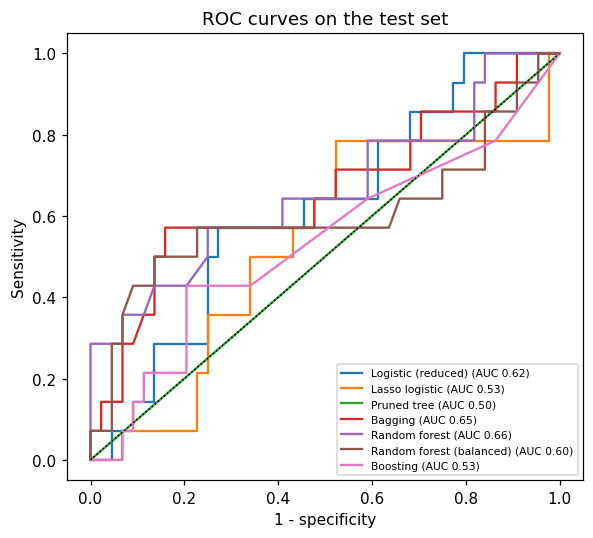

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})", lw=1.5)
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("1 - specificity"); ax.set_ylabel("Sensitivity")
ax.set_title("ROC curves on the test set"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 6. Which predictors matter?

Variable importance from the random forest (mean decrease in impurity) and from boosting. Importance scores from trees are only suggestive when predictors are correlated, so I look at the pattern, not the exact order.

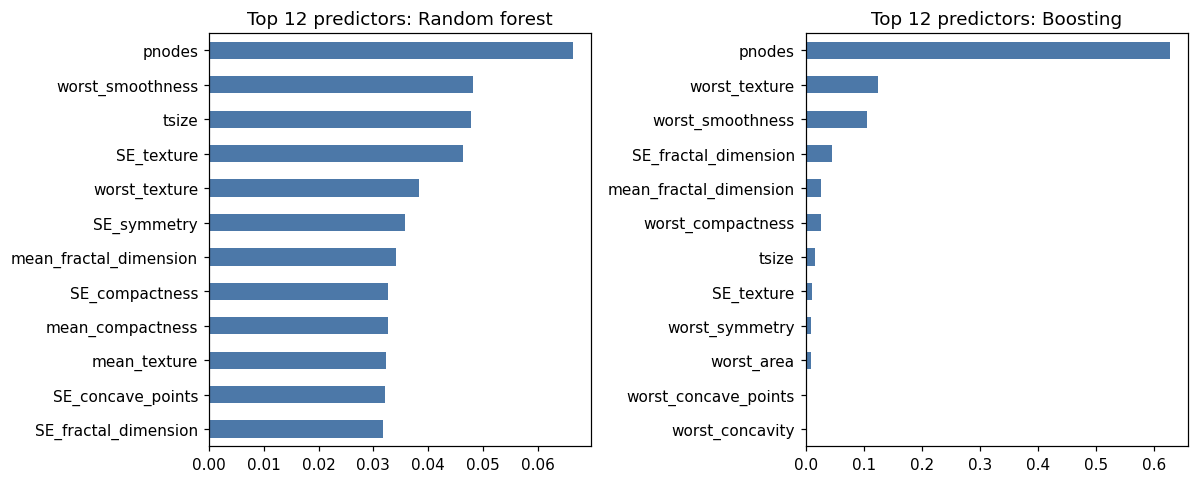

Rank of the clinical predictors (1 = most important):
        Random forest  Boosting
pnodes              1         1
tsize               3         7


In [11]:
imp = pd.DataFrame({"Random forest": pd.Series(rf.feature_importances_, index=X.columns),
                    "Boosting": pd.Series(gbm.feature_importances_, index=X.columns)})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, imp.columns):
    imp[col].sort_values().tail(12).plot.barh(ax=ax, color="#4C78A8")
    ax.set_title(f"Top 12 predictors: {col}")
plt.tight_layout(); plt.show()

ranks = imp.rank(ascending=False).astype(int)
print("Rank of the clinical predictors (1 = most important):")
print(ranks.loc[["pnodes", "tsize"]])

## 7. Choosing a decision threshold without touching the test set

At 0.5, most models flag almost no recurrences. A better threshold can be chosen with Youden's index (sensitivity + specificity - 1), but it must be chosen using **training data only**: here from out-of-fold predictions on the training set. Choosing it on the test set would give optimistic results.

In [12]:
oof = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5000)),
                        X_train[reduced], y_train, cv=cv10, method="predict_proba")[:, 1]
fpr, tpr, thr = roc_curve(y_train, oof)
t_star = thr[(tpr - fpr).argmax()]
print(f"Youden threshold from out-of-fold training predictions: {t_star:.3f}")

p_test = probs["Logistic (reduced)"]
res_t = pd.DataFrame({"threshold 0.5": metrics(y_test, p_test, 0.5),
                      f"threshold {t_star:.2f}": metrics(y_test, p_test, t_star)}).T.round(3)
display(res_t)
print(confusion_matrix(y_test, (p_test > t_star).astype(int), labels=[0, 1]),
      " <- rows: actual no recurrence / recurrence; columns: predicted")

Youden threshold from out-of-fold training predictions: 0.155


,Accuracy,Sensitivity,Specificity,AUC
threshold 0.5,0.707,0.143,0.886,0.617
threshold 0.16,0.448,0.643,0.386,0.617


[[17 27]
 [ 5  9]]  <- rows: actual no recurrence / recurrence; columns: predicted


## 8. How stable are these conclusions? Repeated cross-validation

The test set has only 13 recurrences, so its AUCs are noisy. As a stability check I repeat 5-fold cross-validation three times on all 194 patients with the tuned settings. This is **not** an unbiased estimate (the settings were tuned on the training split), but it shows how much the ranking of methods moves from split to split.

In [13]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv_models = {
    "Logistic (reduced)": (make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=5000)), reduced),
    "Lasso logistic":     (lasso_pipe(C_1se), list(X.columns)),
    "Random forest":      (RandomForestClassifier(n_estimators=300, max_features="sqrt", random_state=SEED), list(X.columns)),
    "Random forest (balanced)": (BalancedRandomForestClassifier(n_estimators=300, max_features="sqrt", sampling_strategy="all",
                                                               replacement=True, bootstrap=False, random_state=SEED), list(X.columns)),
    "Boosting":           (make_gbm(best_trees), list(X.columns)),
}
rows = {}
for name, (m, cols) in cv_models.items():
    s = cross_val_score(m, X[cols], y, cv=rcv, scoring="roc_auc")
    rows[name] = {"mean AUC": s.mean(), "SD across folds": s.std(ddof=1), "min": s.min(), "max": s.max()}
display(pd.DataFrame(rows).T.round(3))

,mean AUC,SD across folds,min,max
Logistic (reduced),0.649,0.092,0.519,0.793
Lasso logistic,0.613,0.083,0.504,0.766
Random forest,0.577,0.101,0.409,0.766
Random forest (balanced),0.596,0.106,0.431,0.808
Boosting,0.535,0.096,0.380,0.711


## 9. Findings and limitations

**What the results show (stratified split, seed 1; numbers will differ with another seed)**

* **Predictive power is modest.** Test AUCs run from 0.50 to 0.66: random forest 0.66, bagging 0.65, reduced logistic 0.62, balanced forest 0.60, boosting 0.53, lasso 0.53, and the pruned tree 0.50 (it collapses to a single node, so it cannot rank anyone).
* **Accuracy is misleading.** Always predicting "no recurrence" scores 0.759 on the test set. Only the random forest (0.810) beats that, and six of the seven models flag fewer than a third of recurrences at the default threshold. The balanced forest finds the most (sensitivity 0.57) but at lower specificity (0.77) and lower accuracy (0.72).
* **Nodal status is the most consistent signal.** `pnodes` ranks first in both the random forest and boosting importance, is the only individually significant coefficient in the reduced logistic regression (p = 0.023), and is the largest coefficient in the lasso at the 1-SE penalty. Tumour size is less consistent (third in the forest, seventh in boosting).
* **The evidence for the nuclear features is not stable.** The likelihood-ratio test of the four nuclear features, added to tumour size and nodes, gives p = 0.54 on this split. My R analysis found p = 0.037 on a different split. A conclusion that flips between random splits should not be reported as a finding.
* **Moving the threshold trades one error for another.** A threshold of 0.155, chosen from out-of-fold training predictions, flags 9 of the 14 test recurrences (sensitivity 0.64) but raises 27 false alarms among 44 non-recurrent patients (specificity 0.39). The ranking quality (AUC 0.62) is unchanged.
* **Single-split rankings are noisy.** In repeated cross-validation, AUCs average 0.54 to 0.65 with a standard deviation of about 0.09 to 0.11 across folds, and the best method on this test split (the random forest) is not the best in repeated cross-validation (the reduced logistic regression is). Differences between methods are within noise.

**How this differs from the R version.** The split, the lasso penalty grid, the definition of boosting tree size and the balanced forest implementation all differ between the R and Python tools, so the numbers are not identical. The qualitative story is the same: modest predictive power, a misleading accuracy figure, nodal status as the most consistent predictor, and a pruned tree that collapses to the root. The one result that did not carry over is the likelihood-ratio test.

**Limitations**

* **Censoring.** Treating recurrence as a plain yes/no outcome treats patients without a recorded recurrence as disease-free, though some may simply have short follow-up. Survival analysis (Kaplan-Meier, Cox) would use the follow-up time properly.
* **Small sample.** 194 patients with 46 recurrences, and only 14 recurrences in the test set. Every metric carries large uncertainty.
* **One split.** The repeated cross-validation in section 8 reuses data that informed tuning, so it checks stability, not unbiased performance. A nested cross-validation would be the next step.
* **Correlated predictors.** Several image features measure overlapping aspects of the same tumour, so importance rankings and which feature the lasso keeps are somewhat arbitrary.
* **Multiple comparisons.** Over 30 candidate predictors and seven models were considered, with no correction.
* **Not clinical advice.** This is a methods exercise on a public benchmark data set.

## References

* Wolberg, W., Street, W. and Mangasarian, O. (1995). *Breast Cancer Wisconsin (Prognostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5GK50
* James, G., Witten, D., Hastie, T. and Tibshirani, R. (2023). *An Introduction to Statistical Learning*, 2nd edition.
* Python packages: pandas, NumPy, SciPy, statsmodels, scikit-learn, imbalanced-learn, matplotlib.